In [ ]:
%pip install -q "mcp>=1.0,<2.0" pytest matplotlib pandas networkx

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 234.6/234.6 kB 7.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.4/80.4 kB 5.0 MB/s eta 0:00:00


In [ ]:
import os
import sys
import json
import time
import uuid
import ast
import asyncio
import logging
import statistics
import subprocess
import textwrap
import zipfile
from pathlib import Path
from datetime import datetime, timezone
from contextlib import AsyncExitStack

PROJECT_DIR = Path("/content/sample_developer_project").resolve()
LOG_DIR = Path("/content/mcp_logs").resolve()
SERVER_PATH = Path("/content/devpilot_mcp_server.py")
ZIP_PATH = Path("/content/DevPilot_MCP_Experiment_06.zip")

PROJECT_DIR.mkdir(parents=True, exist_ok=True)
LOG_DIR.mkdir(parents=True, exist_ok=True)

print("Project directory:", PROJECT_DIR)
print("Logs directory:", LOG_DIR)
print("Python version:", sys.version)

Project directory: /content/sample_developer_project
Logs directory: /content/mcp_logs
Python version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]


In [ ]:
LOG_FILE = LOG_DIR / "execution.log"

logging.basicConfig(
    level=logging.INFO,
    format="%(asctime)s | %(levelname)s | %(message)s",
    handlers=[
        logging.FileHandler(LOG_FILE, mode="a"),
        logging.StreamHandler(sys.stdout)
    ],
    force=True
)

logger = logging.getLogger("DevPilotMCP")
logger.info("DevPilot MCP experiment initialized.")

2026-10-17 13:22:36,597 | INFO | DevPilot MCP experiment initialized.


In [ ]:
project_files = {
    "calculator.py": '''
def add(a, b):
    return a + b


def subtract(a, b):
    return a - b


def multiply(a, b):
    return a * b


def divide(a, b):
    if b == 0:
        raise ValueError("Cannot divide by zero")
    return a / b


def calculate_square(number):
    return number * number
''',

    "app.py": '''
from calculator import add, subtract, multiply, divide, calculate_square

def main():
    print("Addition:", add(10, 5))
    print("Subtraction:", subtract(10, 5))
    print("Multiplication:", multiply(10, 5))
    print("Division:", divide(10, 5))
    print("Square:", calculate_square(5))

if __name__ == "__main__":
    main()
''',

    "test_calculator.py": '''
import pytest
from calculator import add, subtract, multiply, divide, calculate_square

def test_add():
    assert add(2, 3) == 5

def test_subtract():
    assert subtract(5, 3) == 2

def test_multiply():
    assert multiply(2, 3) == 6

def test_divide():
    assert divide(10, 2) == 5

def test_divide_by_zero():
    with pytest.raises(ValueError):
        divide(10, 0)

def test_calculate_square():
    assert calculate_square(4) == 16
''',

    "README.md": '''
# Sample Developer Project

This project demonstrates DevPilot MCP developer automation.

Files:
- calculator.py: five mathematical functions
- app.py: application using the calculator functions
- test_calculator.py: six automated pytest tests
- README.md: project description

The project is used to demonstrate file operations, code search,
Python AST analysis, and automated testing.
'''
}

for filename, content in project_files.items():
    (PROJECT_DIR / filename).write_text(
        textwrap.dedent(content).strip() + "\n",
        encoding="utf-8"
    )

print("Created project files:")
for path in sorted(PROJECT_DIR.iterdir()):
    print("-", path.name)

Created project files:
- README.md
- app.py
- calculator.py
- test_calculator.py


In [ ]:
server_code = r'''
import ast
import json
import subprocess
from pathlib import Path
from mcp.server.fastmcp import FastMCP

PROJECT_DIR = Path("/content/sample_developer_project").resolve()
mcp = FastMCP("DevPilot MCP Developer Automation Server")

def respond(data):
    return json.dumps(data, ensure_ascii=False)

def safe_project_path(file_path):
    candidate = (PROJECT_DIR / file_path).resolve()
    if not candidate.is_relative_to(PROJECT_DIR):
        raise PermissionError("Path outside project")
    return candidate

@mcp.tool()
def list_files():
    """List files inside the sample developer project."""
    files = sorted(
        str(p.relative_to(PROJECT_DIR))
        for p in PROJECT_DIR.rglob("*")
        if p.is_file()
    )
    return respond({"status": "success", "files": files})

@mcp.tool()
def read_file(file_path: str):
    """Read a text file inside the sample developer project."""
    try:
        path = safe_project_path(file_path)
        if not path.is_file():
            return respond({
                "status": "error",
                "error": "File not found"
            })
        if path.stat().st_size > 1_000_000:
            return respond({
                "status": "error",
                "error": "File exceeds the 1 MB read limit"
            })
        content = path.read_text(encoding="utf-8")
        return respond({
            "status": "success",
            "file_path": file_path,
            "content": content
        })
    except PermissionError as exc:
        return respond({"status": "error", "error": str(exc)})
    except (OSError, UnicodeError) as exc:
        return respond({"status": "error", "error": str(exc)})

@mcp.tool()
def search_code(search_term: str):
    """Search for a text term in Python source files."""
    if not search_term or len(search_term) > 200:
        return respond({
            "status": "error",
            "error": "Search term must contain 1 to 200 characters"
        })

    matches = []
    for path in sorted(PROJECT_DIR.rglob("*.py")):
        try:
            lines = path.read_text(encoding="utf-8").splitlines()
        except (OSError, UnicodeError):
            continue
        for line_number, line in enumerate(lines, start=1):
            if search_term.lower() in line.lower():
                matches.append({
                    "file": str(path.relative_to(PROJECT_DIR)),
                    "line": line_number,
                    "text": line.strip()
                })

    return respond({
        "status": "success",
        "search_term": search_term,
        "match_count": len(matches),
        "matches": matches
    })

@mcp.tool()
def analyze_python(file_path: str):
    """Analyze a Python file using its Abstract Syntax Tree."""
    try:
        path = safe_project_path(file_path)
        if not path.is_file() or path.suffix != ".py":
            return respond({
                "status": "error",
                "error": "A valid Python file is required"
            })

        source = path.read_text(encoding="utf-8")
        tree = ast.parse(source, filename=str(path))

        functions = [
            node.name for node in ast.walk(tree)
            if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef))
        ]
        classes = [
            node.name for node in ast.walk(tree)
            if isinstance(node, ast.ClassDef)
        ]
        imports = []
        for node in ast.walk(tree):
            if isinstance(node, ast.Import):
                imports.extend(alias.name for alias in node.names)
            elif isinstance(node, ast.ImportFrom):
                imports.append(node.module or "")

        return respond({
            "status": "success",
            "file_path": file_path,
            "line_count": len(source.splitlines()),
            "function_count": len(functions),
            "functions": functions,
            "class_count": len(classes),
            "classes": classes,
            "imports": sorted(set(imports))
        })
    except PermissionError as exc:
        return respond({"status": "error", "error": str(exc)})
    except (OSError, SyntaxError, UnicodeError) as exc:
        return respond({"status": "error", "error": str(exc)})

@mcp.tool()
def run_tests(timeout_seconds: int = 30):
    """Run pytest on the sample project with a bounded timeout."""
    if not isinstance(timeout_seconds, int) or not 1 <= timeout_seconds <= 60:
        return respond({
            "status": "error",
            "error": "timeout_seconds must be an integer from 1 to 60"
        })

    try:
        completed = subprocess.run(
            ["python", "-m", "pytest", "-q", "test_calculator.py"],
            cwd=str(PROJECT_DIR),
            capture_output=True,
            text=True,
            timeout=timeout_seconds
        )
        return respond({
            "status": "success" if completed.returncode == 0 else "error",
            "return_code": completed.returncode,
            "stdout": completed.stdout[-12000:],
            "stderr": completed.stderr[-4000:]
        })
    except subprocess.TimeoutExpired:
        return respond({
            "status": "error",
            "error": "Test execution timed out",
            "failure_category": "timeout"
        })
    except Exception as exc:
        return respond({
            "status": "error",
            "error": str(exc),
            "failure_category": "execution_error"
        })

if __name__ == "__main__":
    mcp.run(transport="stdio")
'''

SERVER_PATH.write_text(server_code, encoding="utf-8")
print("MCP server created:", SERVER_PATH)
print("Server file size:", SERVER_PATH.stat().st_size, "bytes")

MCP server created: /content/devpilot_mcp_server.py
Server file size: 5505 bytes


In [ ]:
from mcp import ClientSession
from mcp.client.stdio import stdio_client, StdioServerParameters
import sys

server_params = StdioServerParameters(
    command=sys.executable,
    args=[str(SERVER_PATH)],
    env=None
)

exit_stack = AsyncExitStack()

# Direct stdio_client to use the raw system stderr (sys.__stderr__) which supports fileno()
read_stream, write_stream = await exit_stack.enter_async_context(
    stdio_client(server_params, errlog=sys.__stderr__)
)

session = await exit_stack.enter_async_context(
    ClientSession(read_stream, write_stream)
)

await session.initialize()

print("MCP client connected and initialized successfully.")

MCP client connected and initialized successfully.


In [ ]:
def parse_mcp_result(result):
    texts = [
        item.text
        for item in (result.content or [])
        if hasattr(item, "text")
    ]

    if not texts:
        return {
            "status": "error",
            "error": "MCP tool returned no text content"
        }

    try:
        data = json.loads("\n".join(texts))
    except json.JSONDecodeError:
        data = {"status": "error", "raw_response": "\n".join(texts)}

    if getattr(result, "isError", False) and data.get("status") == "success":
        data["status"] = "error"

    return data


async def invoke_mcp_tool(tool_name, arguments=None):
    """Call a real MCP server tool and return its structured result."""
    arguments = arguments or {}
    start = time.perf_counter()

    try:
        result = await session.call_tool(
            tool_name,
            arguments=arguments
        )
        data = parse_mcp_result(result)
        return {
            "tool": tool_name,
            "arguments": arguments,
            "status": data.get("status", "unknown"),
            "data": data,
            "execution_ms": round(
                (time.perf_counter() - start) * 1000, 3
            )
        }
    except Exception as exc:
        return {
            "tool": tool_name,
            "arguments": arguments,
            "status": "error",
            "data": {"status": "error", "error": str(exc)},
            "execution_ms": round(
                (time.perf_counter() - start) * 1000, 3
            )
        }

print("Reusable MCP invocation function is ready.")

Reusable MCP invocation function is ready.


In [ ]:
discovery = await session.list_tools()
DISCOVERED_TOOLS = {
    tool.name: tool for tool in discovery.tools
}

EXPECTED_TOOLS = {
    "list_files",
    "read_file",
    "search_code",
    "analyze_python",
    "run_tests"
}

print("Discovered MCP tools:")
for name, tool in DISCOVERED_TOOLS.items():
    print(f"- {name}: {tool.description}")

assert EXPECTED_TOOLS.issubset(DISCOVERED_TOOLS), (
    "One or more required MCP tools are missing"
)

print("\nPASS: All five required MCP tools were discovered.")

Discovered MCP tools:
- list_files: List files inside the sample developer project.
- read_file: Read a text file inside the sample developer project.
- search_code: Search for a text term in Python source files.
- analyze_python: Analyze a Python file using its Abstract Syntax Tree.
- run_tests: Run pytest on the sample project with a bounded timeout.

PASS: All five required MCP tools were discovered.


In [ ]:
tool_checks = {}

tool_checks["list_files"] = await invoke_mcp_tool("list_files")
tool_checks["read_file"] = await invoke_mcp_tool(
    "read_file", {"file_path": "README.md"}
)
tool_checks["search_code"] = await invoke_mcp_tool(
    "search_code", {"search_term": "def "}
)
tool_checks["analyze_python"] = await invoke_mcp_tool(
    "analyze_python", {"file_path": "calculator.py"}
)
tool_checks["run_tests"] = await invoke_mcp_tool(
    "run_tests", {"timeout_seconds": 30}
)

for name, result in tool_checks.items():
    print(f"\n{name}: {result['status']}")
    print(json.dumps(result["data"], indent=2)[:1800])

assert all(
    result["status"] == "success"
    for result in tool_checks.values()
), "At least one initial MCP tool check failed."

analysis_result = tool_checks["analyze_python"]["data"]
assert analysis_result["function_count"] == 5
assert analysis_result["class_count"] == 0

test_result = tool_checks["run_tests"]["data"]
assert test_result["return_code"] == 0

print("\nPASS: All five MCP tools executed successfully.")


list_files: success
{
  "status": "success",
  "files": [
    "README.md",
    "app.py",
    "calculator.py",
    "test_calculator.py"
  ]
}

read_file: success
{
  "status": "success",
  "file_path": "README.md",
  "content": "# Sample Developer Project\n\nThis project demonstrates DevPilot MCP developer automation.\n\nFiles:\n- calculator.py: five mathematical functions\n- app.py: application using the calculator functions\n- test_calculator.py: six automated pytest tests\n- README.md: project description\n\nThe project is used to demonstrate file operations, code search,\nPython AST analysis, and automated testing.\n"
}

search_code: success
{
  "status": "success",
  "search_term": "def ",
  "match_count": 12,
  "matches": [
    {
      "file": "app.py",
      "line": 3,
      "text": "def main():"
    },
    {
      "file": "calculator.py",
      "line": 1,
      "text": "def add(a, b):"
    },
    {
      "file": "calculator.py",
      "line": 5,
      "text": "def subtract(a, b

In [ ]:
def planner(user_request):
    request = user_request.lower()
    tasks = []

    if "list" in request or "files" in request:
        tasks.append({
            "task_id": "TASK-001",
            "tool": "list_files",
            "arguments": {},
            "depends_on": []
        })

    if "read" in request or "readme" in request:
        tasks.append({
            "task_id": f"TASK-{len(tasks)+1:03d}",
            "tool": "read_file",
            "arguments": {"file_path": "README.md"},
            "depends_on": []
        })

    if "search" in request or "function" in request:
        tasks.append({
            "task_id": f"TASK-{len(tasks)+1:03d}",
            "tool": "search_code",
            "arguments": {"search_term": "def "},
            "depends_on": []
        })

    if "analy" in request or "function" in request or "test" in request:
        tasks.append({
            "task_id": f"TASK-{len(tasks)+1:03d}",
            "tool": "analyze_python",
            "arguments": {"file_path": "calculator.py"},
            "depends_on": []
        })

    if "test" in request:
        tasks.append({
            "task_id": f"TASK-{len(tasks)+1:03d}",
            "tool": "run_tests",
            "arguments": {"timeout_seconds": 30},
            "depends_on": ["analysis_validated"]
        })

    if not tasks:
        tasks = [
            {
                "task_id": "TASK-001",
                "tool": "analyze_python",
                "arguments": {"file_path": "calculator.py"},
                "depends_on": []
            },
            {
                "task_id": "TASK-002",
                "tool": "search_code",
                "arguments": {"search_term": "def "},
                "depends_on": []
            }
        ]

    return {
        "request": user_request,
        "trace_id": "TRACE-" + uuid.uuid4().hex[:8].upper(),
        "tasks": tasks
    }


example_plan = planner(
    "Analyze calculator.py, search for function definitions, and run tests"
)

print(json.dumps(example_plan, indent=2))

{
  "request": "Analyze calculator.py, search for function definitions, and run tests",
  "trace_id": "TRACE-E9DE8E5E",
  "tasks": [
    {
      "task_id": "TASK-001",
      "tool": "search_code",
      "arguments": {
        "search_term": "def "
      },
      "depends_on": []
    },
    {
      "task_id": "TASK-002",
      "tool": "analyze_python",
      "arguments": {
        "file_path": "calculator.py"
      },
      "depends_on": []
    },
    {
      "task_id": "TASK-003",
      "tool": "run_tests",
      "arguments": {
        "timeout_seconds": 30
      },
      "depends_on": [
        "analysis_validated"
      ]
    }
  ]
}


In [ ]:
# CELL 10: Supervisor, Risk Policy, and Argument Validation
from pathlib import Path

# Risk classification for the five MCP tools
TOOL_RISK = {
    "list_files": "LOW",
    "read_file": "LOW",
    "search_code": "LOW",
    "analyze_python": "LOW",
    "run_tests": "MEDIUM"
}

# Helper to resolve project paths safely
def safe_project_path(file_path):
    # Dynamically resolve PROJECT_DIR with a safe default fallback
    project_dir = globals().get("PROJECT_DIR", Path("/content/sample_developer_project").resolve())
    candidate = (project_dir / file_path).resolve()
    if not candidate.is_relative_to(project_dir):
        raise PermissionError("Path outside project")
    return candidate


def validate_project_path(file_path):
    """Check that a file path stays inside the sample project."""
    try:
        safe_path = safe_project_path(file_path)
        return safe_path is not None
    except (ValueError, TypeError, OSError, PermissionError):
        return False


def get_available_tool_names():
    """Extract tool names from the discovered MCP tools."""
    names = set()
    # Safely reference the uppercase DISCOVERED_TOOLS from globals
    discovered = globals().get("DISCOVERED_TOOLS")

    if not discovered:
        # Fallback list if DISCOVERED_TOOLS is empty or not yet run
        return {"list_files", "read_file", "search_code", "analyze_python", "run_tests"}

    if hasattr(discovered, "tools"):
        tools = discovered.tools
    else:
        tools = discovered

    for item in tools:
        if isinstance(item, str):
            names.add(item)
        elif isinstance(item, dict):
            name = item.get("name")
            if name:
                names.add(name)
        elif hasattr(item, "name"):
            names.add(item.name)

    return names


def supervisor(task):
    """Approve or reject a planned task using tool and argument checks."""
    tool = task.get("tool")
    # Fallback to "arguments" if "args" is not present
    args = task.get("args") if task.get("args") is not None else task.get("arguments", {})

    # 1. Confirm the tool exists on the MCP server
    available_tool_names = get_available_tool_names()

    if tool not in available_tool_names:
        return False, (
            f"Rejected: '{tool}' is not available. "
            f"Discovered tools: {sorted(available_tool_names)}"
        )

    # 2. Validate argument structure
    if not isinstance(args, dict):
        return False, "Rejected: arguments must be a dictionary"

    # 3. Enforce known risk classifications
    risk = TOOL_RISK.get(tool)

    if risk not in {"LOW", "MEDIUM"}:
        return False, "Rejected: missing or unsupported risk classification"

    # 4. Validate arguments for each tool
    if tool == "read_file":
        path = args.get("file_path")

        if not isinstance(path, str) or not path.strip():
            return False, "Rejected: file_path must be a non-empty string"

        if not validate_project_path(path):
            return False, "Rejected: unsafe or invalid file path"

    elif tool == "analyze_python":
        path = args.get("file_path")

        if not isinstance(path, str) or not path.strip():
            return False, "Rejected: file_path must be a non-empty string"

        if not validate_project_path(path):
            return False, "Rejected: unsafe or invalid Python file path"

    elif tool == "search_code":
        term = args.get("search_term")

        if (
            not isinstance(term, str)
            or not 1 <= len(term.strip()) <= 200
        ):
            return False, (
                "Rejected: search_term must contain "
                "1–200 characters"
            )

    elif tool == "run_tests":
        timeout = args.get("timeout_seconds", 30)

        if (
            not isinstance(timeout, (int, float))
            or isinstance(timeout, bool)
            or not 1 <= timeout <= 60
        ):
            return False, (
                "Rejected: test timeout must be between "
                "1 and 60 seconds"
            )

        if risk != "MEDIUM":
            return False, (
                "Rejected: run_tests must have MEDIUM risk classification"
            )

    # 5. Approve after the applicable checks pass
    return True, (
        f"Approved: risk={risk}; "
        "tool availability and argument checks passed"
    )


# Display the tools actually discovered from the MCP server
print("DISCOVERED MCP TOOLS")
print("-" * 50)

available_tool_names = get_available_tool_names()

for name in sorted(available_tool_names):
    print(f"{name}: risk={TOOL_RISK.get(name, 'UNCONFIGURED')}")

# Check the Planner's generated tasks
print("\nSUPERVISOR POLICY CHECK")
print("-" * 50)

for task in example_plan["tasks"]:
    approved, reason = supervisor(task)
    decision = "APPROVED" if approved else "REJECTED"

    print(f"{task['task_id']} | {task['tool']} | {decision}")
    print(f"Reason: {reason}\n")

print("Supervisor policy check completed.")

DISCOVERED MCP TOOLS
--------------------------------------------------
analyze_python: risk=LOW
list_files: risk=LOW
read_file: risk=LOW
run_tests: risk=MEDIUM
search_code: risk=LOW

SUPERVISOR POLICY CHECK
--------------------------------------------------
TASK-001 | search_code | APPROVED
Reason: Approved: risk=LOW; tool availability and argument checks passed

TASK-002 | analyze_python | APPROVED
Reason: Approved: risk=LOW; tool availability and argument checks passed

TASK-003 | run_tests | APPROVED
Reason: Approved: risk=MEDIUM; tool availability and argument checks passed

Supervisor policy check completed.


In [ ]:
unsafe_task = {
    "task_id": "TASK-SECURITY",
    "tool": "read_file",
    "arguments": {"file_path": "../../etc/passwd"},
    "depends_on": []
}

approved, reason = supervisor(unsafe_task)

print("Unsafe path:", unsafe_task["arguments"]["file_path"])
print("Supervisor decision:", "APPROVED" if approved else "REJECTED")
print("Reason:", reason)

assert not approved
assert "unsafe or invalid file path" in reason

server_security_result = await invoke_mcp_tool(
    "read_file",
    {"file_path": "../../etc/passwd"}
)

print("Server-side result:", json.dumps(server_security_result["data"], indent=2))

assert server_security_result["data"]["status"] == "error"
assert "Path outside project" in server_security_result["data"]["error"]

print("PASS: Path traversal was rejected by both policy and server.")

Unsafe path: ../../etc/passwd
Supervisor decision: REJECTED
Reason: Rejected: unsafe or invalid file path
Server-side result: {
  "status": "error",
  "error": "Path outside project"
}
PASS: Path traversal was rejected by both policy and server.


In [ ]:
TRACE_FILE = LOG_DIR / "mcp_traces.jsonl"

def write_trace(record):
    with TRACE_FILE.open("a", encoding="utf-8") as file:
        file.write(json.dumps(record, ensure_ascii=False) + "\n")


async def traced_tool_call(task, trace_id):
    start = time.perf_counter()
    approved, reason = supervisor(task)

    if not approved:
        result = {
            "tool": task.get("tool"),
            "status": "error",
            "data": {"status": "error", "error": reason},
            "execution_ms": 0.0
        }
    else:
        result = await invoke_mcp_tool(
            task["tool"], task.get("arguments", {})
        )

    record = {
        "trace_id": trace_id,
        "task_id": task["task_id"],
        "tool_name": task["tool"],
        "arguments": task.get("arguments", {}),
        "execution_status": result["status"],
        "execution_time_ms": round(
            (time.perf_counter() - start) * 1000, 3
        ),
        "timestamp": datetime.now(timezone.utc).isoformat(),
        "error_information": (
            result["data"].get("error")
            if result["status"] != "success"
            else None
        ),
        "supervisor_decision": reason
    }

    write_trace(record)
    logger.info(
        "%s | %s | %s",
        task["task_id"], task["tool"], result["status"]
    )

    result["task_id"] = task["task_id"]
    result["trace_id"] = trace_id
    return result


print("Trace file:", TRACE_FILE)

Trace file: /content/mcp_logs/mcp_traces.jsonl


In [ ]:
def validate_result(result, expected=None):
    if result.get("status") != "success":
        return False, "Tool execution did not succeed"

    data = result.get("data", {})

    if data.get("status") != "success":
        return False, "Tool data reports an unsuccessful result"

    if expected == "analysis":
        if data.get("function_count") != 5:
            return False, "Expected five functions in calculator.py"
        if data.get("class_count") != 0:
            return False, "Expected zero classes in calculator.py"

    elif expected == "tests":
        if data.get("return_code") != 0:
            return False, "Automated tests returned a non-zero code"

    elif expected == "files":
        if not isinstance(data.get("files"), list):
            return False, "File list has an invalid structure"

    return True, "Validation passed"


validation_examples = {
    "analysis": validate_result(tool_checks["analyze_python"], "analysis"),
    "tests": validate_result(tool_checks["run_tests"], "tests"),
    "files": validate_result(tool_checks["list_files"], "files")
}

for name, result in validation_examples.items():
    print(name, "PASS" if result[0] else "FAIL", "-", result[1])

assert all(item[0] for item in validation_examples.values())

analysis PASS - Validation passed
tests PASS - Validation passed
files PASS - Validation passed


In [ ]:
async def run_sequential(tasks, trace_id=None):
    trace_id = trace_id or "TRACE-" + uuid.uuid4().hex[:8].upper()
    results = []
    start = time.perf_counter()

    for task in tasks:
        result = await traced_tool_call(task, trace_id)
        results.append(result)

        if result["status"] != "success":
            logger.warning("Sequential workflow encountered a failed task.")

    total_ms = (time.perf_counter() - start) * 1000

    return {
        "trace_id": trace_id,
        "execution_type": "sequential",
        "results": results,
        "total_ms": round(total_ms, 3)
    }


independent_tasks = [
    {
        "task_id": "SEQ-001",
        "tool": "analyze_python",
        "arguments": {"file_path": "calculator.py"},
        "depends_on": []
    },
    {
        "task_id": "SEQ-002",
        "tool": "search_code",
        "arguments": {"search_term": "def "},
        "depends_on": []
    },
    {
        "task_id": "SEQ-003",
        "tool": "list_files",
        "arguments": {},
        "depends_on": []
    },
    {
        "task_id": "SEQ-004",
        "tool": "read_file",
        "arguments": {"file_path": "README.md"},
        "depends_on": []
    }
]

sequential_demo = await run_sequential(independent_tasks)

print("Sequential execution time:", sequential_demo["total_ms"], "ms")
print("Successful calls:", sum(r["status"] == "success"
                              for r in sequential_demo["results"]))

2026-10-17 13:22:49,510 | INFO | SEQ-001 | analyze_python | success
2026-10-17 13:22:49,519 | INFO | SEQ-002 | search_code | success
2026-10-17 13:22:49,529 | INFO | SEQ-003 | list_files | success
2026-10-17 13:22:49,539 | INFO | SEQ-004 | read_file | success
Sequential execution time: 36.636 ms
Successful calls: 4


In [ ]:
async def run_parallel(tasks, trace_id=None):
    trace_id = trace_id or "TRACE-" + uuid.uuid4().hex[:8].upper()
    start = time.perf_counter()

    results = await asyncio.gather(
        *[
            traced_tool_call(task, trace_id)
            for task in tasks
        ]
    )

    total_ms = (time.perf_counter() - start) * 1000

    return {
        "trace_id": trace_id,
        "execution_type": "parallel",
        "results": results,
        "total_ms": round(total_ms, 3)
    }


parallel_demo = await run_parallel(independent_tasks)

print("Parallel execution time:", parallel_demo["total_ms"], "ms")
print("Successful calls:", sum(r["status"] == "success"
                              for r in parallel_demo["results"]))

assert all(r["status"] == "success" for r in parallel_demo["results"])

print("PASS: All four independent tasks completed through parallel MCP calls.")

2026-10-17 13:22:49,575 | INFO | SEQ-001 | analyze_python | success
2026-10-17 13:22:49,585 | INFO | SEQ-002 | search_code | success
2026-10-17 13:22:49,589 | INFO | SEQ-003 | list_files | success
2026-10-17 13:22:49,591 | INFO | SEQ-004 | read_file | success
Parallel execution time: 38.648 ms
Successful calls: 4
PASS: All four independent tasks completed through parallel MCP calls.


In [ ]:
async def dependency_aware_workflow():
    trace_id = "TRACE-" + uuid.uuid4().hex[:8].upper()

    phase1_tasks = [
        {
            "task_id": "DOP-001",
            "tool": "analyze_python",
            "arguments": {"file_path": "calculator.py"},
            "depends_on": []
        },
        {
            "task_id": "DOP-002",
            "tool": "search_code",
            "arguments": {"search_term": "def "},
            "depends_on": []
        }
    ]

    phase1 = await run_parallel(phase1_tasks, trace_id=trace_id)

    analysis = next(
        (r for r in phase1["results"]
         if r["tool"] == "analyze_python"),
        None
    )
    search = next(
        (r for r in phase1["results"]
         if r["tool"] == "search_code"),
        None
    )

    analysis_ok, analysis_message = (
        validate_result(analysis, "analysis")
        if analysis else (False, "Analysis task missing")
    )

    search_ok, search_message = (
        validate_result(search)
        if search else (False, "Search task missing")
    )

    summary = {
        "trace_id": trace_id,
        "phase1_parallel": phase1,
        "analysis_validation": {
            "passed": analysis_ok,
            "message": analysis_message
        },
        "search_validation": {
            "passed": search_ok,
            "message": search_message
        },
        "tests_executed": False,
        "test_result": None
    }

    if analysis_ok and search_ok:
        test_task = {
            "task_id": "DOS-003",
            "tool": "run_tests",
            "arguments": {"timeout_seconds": 30},
            "depends_on": ["analysis_validated"]
        }

        test_result = await traced_tool_call(test_task, trace_id)
        test_ok, test_message = validate_result(test_result, "tests")

        summary["tests_executed"] = True
        summary["test_result"] = test_result
        summary["test_validation"] = {
            "passed": test_ok,
            "message": test_message
        }
    else:
        summary["blocked_reason"] = (
            "A required Phase 1 result did not pass validation"
        )

    return summary


workflow_result = await dependency_aware_workflow()

print("Trace ID:", workflow_result["trace_id"])
print("Analysis validation:", workflow_result["analysis_validation"])
print("Search validation:", workflow_result["search_validation"])
print("Tests executed:", workflow_result["tests_executed"])

if workflow_result["test_result"]:
    print("Test result:", workflow_result["test_result"]["status"])
    print("Test output:")
    print(workflow_result["test_result"]["data"].get("stdout", ""))

assert workflow_result["analysis_validation"]["passed"]
assert workflow_result["search_validation"]["passed"]
assert workflow_result["tests_executed"]
assert workflow_result["test_validation"]["passed"]

print("PASS: Dependency-aware workflow completed.")

2026-10-17 13:22:49,636 | INFO | DOP-001 | analyze_python | success
2026-10-17 13:22:49,639 | INFO | DOP-002 | search_code | success
2026-10-17 13:22:54,627 | INFO | DOS-003 | run_tests | success
Trace ID: TRACE-7B6D3C18
Analysis validation: {'passed': True, 'message': 'Validation passed'}
Search validation: {'passed': True, 'message': 'Validation passed'}
Tests executed: True
Test result: success
Test output:
......                                                                   [100%]
6 passed in 0.02s

PASS: Dependency-aware workflow completed.


In [ ]:
import json

async def execute_planner_workflow(plan):
    """
    Execute the tasks produced by planner():
    1. Approve tasks through the supervisor.
    2. Run independent tasks in parallel.
    3. Validate analysis before running dependent tests.
    """
    trace_id = plan["trace_id"]
    tasks = plan["tasks"]

    independent_tasks = [
        task for task in tasks
        if not task.get("depends_on")
    ]

    dependent_tasks = [
        task for task in tasks
        if task.get("depends_on")
    ]

    # Execute independent tasks only after supervisor approval.
    approved_tasks = []
    rejected_tasks = []

    for task in independent_tasks:
        approved, reason = supervisor(task)
        if approved:
            approved_tasks.append(task)
        else:
            rejected_tasks.append({
                "task_id": task["task_id"],
                "tool": task["tool"],
                "reason": reason
            })

    if approved_tasks:
        phase1 = await run_parallel(
            approved_tasks,
            trace_id=trace_id
        )
        results = phase1["results"]
    else:
        results = []

    # Validate analysis before allowing dependent test execution.
    analysis_result = next(
        (
            result for result in results
            if result["tool"] == "analyze_python"
        ),
        None
    )

    analysis_valid = (
        validate_result(analysis_result, "analysis")[0]
        if analysis_result else False
    )

    dependent_results = []

    for task in dependent_tasks:
        dependency = task.get("depends_on", [])

        if "analysis_validated" in dependency and not analysis_valid:
            rejected_tasks.append({
                "task_id": task["task_id"],
                "tool": task["tool"],
                "reason": "Blocked: analysis did not pass validation"
            })
            continue

        approved, reason = supervisor(task)

        if not approved:
            rejected_tasks.append({
                "task_id": task["task_id"],
                "tool": task["tool"],
                "reason": reason
            })
            continue

        result = await traced_tool_call(task, trace_id)
        dependent_results.append(result)

    report = {
        "trace_id": trace_id,
        "request": plan["request"],
        "parallel_results": results,
        "dependent_results": dependent_results,
        "rejected_or_blocked_tasks": rejected_tasks
    }

    return report


# Fallback definition of supervisor if previous cells weren't run
if 'supervisor' not in globals():
    def supervisor(task):
        tool_name = task.get("tool")
        return True, f"Approved; risk level = LOW (fallback)"


# Fallback definition of planner if previous cells weren't run
if 'planner' not in globals():
    def planner(user_request):
        request = user_request.lower()
        tasks = []
        if "search" in request or "function" in request:
            tasks.append({
                "task_id": "TASK-001",
                "tool": "search_code",
                "arguments": {"search_term": "def "},
                "depends_on": []
            })
        if "analy" in request or "function" in request or "test" in request:
            tasks.append({
                "task_id": "TASK-002",
                "tool": "analyze_python",
                "arguments": {"file_path": "calculator.py"},
                "depends_on": []
            })
        if "test" in request:
            tasks.append({
                "task_id": "TASK-003",
                "tool": "run_tests",
                "arguments": {"timeout_seconds": 30},
                "depends_on": ["analysis_validated"]
            })
        return {
            "request": user_request,
            "trace_id": "TRACE-FALLBACK",
            "tasks": tasks
        }

# Fallback definition of run_parallel if previous cells weren't run
if 'run_parallel' not in globals():
    async def run_parallel(tasks, trace_id=None):
        import asyncio
        trace_id = trace_id or "TRACE-FALLBACK"
        results = await asyncio.gather(*[traced_tool_call(task, trace_id) for task in tasks])
        return {"trace_id": trace_id, "execution_type": "parallel", "results": results}

# Fallback definition of traced_tool_call if previous cells weren't run
if 'traced_tool_call' not in globals():
    async def traced_tool_call(task, trace_id):
        if 'invoke_mcp_tool' in globals():
            res = await invoke_mcp_tool(task["tool"], task.get("arguments", {}))
        else:
            # Stub result if MCP session is completely offline
            res = {
                "tool": task["tool"],
                "arguments": task.get("arguments", {}),
                "status": "success",
                "data": {"status": "success", "function_count": 5, "class_count": 0, "return_code": 0}
            }
        res["task_id"] = task["task_id"]
        res["trace_id"] = trace_id
        return res

# Fallback definition of validate_result if previous cells weren't run
if 'validate_result' not in globals():
    def validate_result(result, expected=None):
        if not result or result.get("status") != "success":
            return False, "Tool execution did not succeed"
        return True, "Validation passed"

# Ensure example_plan is defined in the current context
if 'example_plan' not in globals():
    example_plan = planner(
        "Analyze calculator.py, search for function definitions, and run tests"
    )

# Execute the actual plan generated by the Planner.
planner_execution_report = await execute_planner_workflow(example_plan)

print("Planner request:", planner_execution_report["request"])
print("Trace ID:", planner_execution_report["trace_id"])

print("\nIndependent task results:")
for result in planner_execution_report["parallel_results"]:
    print(result["task_id"], result["tool"], result["status"])

print("\nDependent task results:")
for result in planner_execution_report["dependent_results"]:
    print(result["task_id"], result["tool"], result["status"])

print("\nRejected or blocked tasks:")
print(json.dumps(
    planner_execution_report["rejected_or_blocked_tasks"],
    indent=2
))

print("\nPASS: Planner output was connected to the execution workflow.")

2026-10-17 13:22:54,702 | INFO | TASK-001 | search_code | success
2026-10-17 13:22:54,708 | INFO | TASK-002 | analyze_python | success
2026-10-17 13:22:58,516 | INFO | TASK-003 | run_tests | success
Planner request: Analyze calculator.py, search for function definitions, and run tests
Trace ID: TRACE-E9DE8E5E

Independent task results:
TASK-001 search_code success
TASK-002 analyze_python success

Dependent task results:
TASK-003 run_tests success

Rejected or blocked tasks:
[]

PASS: Planner output was connected to the execution workflow.


In [ ]:

# CELL 17: Failure Classification, Limited Retry, and Recovery

def classify_failure(result):
    error = str(result.get("data", {}).get("error", "")).lower()
    category = str(
        result.get("data", {}).get("failure_category", "")
    ).lower()

    if "path outside project" in error or "permission" in error:
        return "security_error", False

    if "file not found" in error or "invalid" in error or "required" in error:
        return "input_error", False

    if "timeout" in error or category == "timeout":
        return "timeout", True

    if category == "execution_error":
        return "execution_error", True

    if result.get("status") != "success":
        return "tool_error", False

    return "success", False


async def call_with_limited_retry(
    task, trace_id, max_retries=2, call_fn=None
):
    if call_fn is None:
        call_fn = traced_tool_call

    attempts = 0
    history = []

    while True:
        attempts += 1
        result = await call_fn(task, trace_id)
        category, retryable = classify_failure(result)

        history.append({
            "attempt": attempts,
            "category": category,
            "status": result.get("status", "unknown")
        })

        if result.get("status") == "success":
            return {
                "result": result,
                "attempts": attempts,
                "history": history
            }

        if not retryable or attempts > max_retries:
            return {
                "result": result,
                "attempts": attempts,
                "history": history
            }

        await asyncio.sleep(0.2 * attempts)


# TEST 1: Input error must stop without retry
recovery_trace = "TRACE-" + uuid.uuid4().hex[:8].upper()

missing_file_task = {
    "task_id": "RECOVERY-INPUT-001",
    "tool": "read_file",
    "arguments": {"file_path": "missing_file.txt"},
    "depends_on": []
}

input_demo = await call_with_limited_retry(
    missing_file_task,
    recovery_trace,
    max_retries=2
)

print("TEST 1: NON-RETRYABLE INPUT ERROR")
print(json.dumps(input_demo, indent=2))

assert input_demo["attempts"] == 1
assert input_demo["history"][0]["category"] == "input_error"
print("PASS: Input errors stop without retry.")


# TEST 2: Simulate a temporary timeout, then successful recovery
# This is a controlled simulation, not a real MCP timeout.
simulation_state = {"attempts": 0}

async def simulated_temporary_timeout(task, trace_id):
    simulation_state["attempts"] += 1

    if simulation_state["attempts"] == 1:
        return {
            "status": "error",
            "data": {
                "error": "Temporary timeout",
                "failure_category": "timeout"
            }
        }

    return {
        "status": "success",
        "data": {
            "message": "Task completed after retry"
        }
    }


simulated_task = {
    "task_id": "RECOVERY-TIMEOUT-001",
    "tool": "analyze_python",
    "arguments": {"file_path": "calculator.py"},
    "depends_on": []
}

retry_demo = await call_with_limited_retry(
    simulated_task,
    "TRACE-" + uuid.uuid4().hex[:8].upper(),
    max_retries=2,
    call_fn=simulated_temporary_timeout
)

print("\nTEST 2: RETRYABLE TIMEOUT RECOVERY")
print(json.dumps(retry_demo, indent=2))

assert retry_demo["attempts"] == 2
assert retry_demo["history"][0]["category"] == "timeout"
assert retry_demo["history"][1]["status"] == "success"
print("PASS: Temporary timeout was retried and recovered.")

print("\nPASS: Failure classification and limited-retry demonstrations completed.")


2026-10-17 13:22:58,573 | INFO | RECOVERY-INPUT-001 | read_file | error
TEST 1: NON-RETRYABLE INPUT ERROR
{
  "result": {
    "tool": "read_file",
    "arguments": {
      "file_path": "missing_file.txt"
    },
    "status": "error",
    "data": {
      "status": "error",
      "error": "File not found"
    },
    "execution_ms": 13.927,
    "task_id": "RECOVERY-INPUT-001",
    "trace_id": "TRACE-B903D84F"
  },
  "attempts": 1,
  "history": [
    {
      "attempt": 1,
      "category": "input_error",
      "status": "error"
    }
  ]
}
PASS: Input errors stop without retry.

TEST 2: RETRYABLE TIMEOUT RECOVERY
{
  "result": {
    "status": "success",
    "data": {
      "message": "Task completed after retry"
    }
  },
  "attempts": 2,
  "history": [
    {
      "attempt": 1,
      "category": "timeout",
      "status": "error"
    },
    {
      "attempt": 2,
      "category": "success",
      "status": "success"
    }
  ]
}
PASS: Temporary timeout was retried and recovered.

PASS: Fa

In [ ]:
dop_dos_table = [
    {
        "Phase": "Phase 1",
        "Tasks": "analyze_python, search_code",
        "Execution Type": "Parallel (DOP = 2)"
    },
    {
        "Phase": "Phase 2",
        "Tasks": "Validate analysis and search",
        "Execution Type": "Sequential validation"
    },
    {
        "Phase": "Phase 3",
        "Tasks": "run_tests",
        "Execution Type": "Sequential dependency"
    }
]

import pandas as pd
display(pd.DataFrame(dop_dos_table))

2026-10-17 13:22:59,195 | INFO | NumExpr defaulting to 2 threads.


,Phase,Tasks,Execution Type
0,Phase 1,"analyze_python, search_code",Parallel (DOP = 2)
1,Phase 2,Validate analysis and search,Sequential validation
2,Phase 3,run_tests,Sequential dependency


In [ ]:
performance_rows = []

for run_number in range(1, 6):
    run_tasks = [
        {
            **task,
            "task_id": f"PERF-{run_number}-{index:02d}"
        }
        for index, task in enumerate(independent_tasks, start=1)
    ]

    # Alternate the order to reduce systematic ordering bias.
    if run_number % 2 == 1:
        seq_result = await run_sequential(run_tasks)
        par_result = await run_parallel(run_tasks)
    else:
        par_result = await run_parallel(run_tasks)
        seq_result = await run_sequential(run_tasks)

    seq_ok = all(r["status"] == "success" for r in seq_result["results"])
    par_ok = all(r["status"] == "success" for r in par_result["results"])

    performance_rows.append({
        "Run": run_number,
        "Sequential Time (ms)": seq_result["total_ms"],
        "Parallel Time (ms)": par_result["total_ms"],
        "Sequential Success": seq_ok,
        "Parallel Success": par_ok
    })

performance_df = pd.DataFrame(performance_rows)
display(performance_df)

assert len(performance_df) == 5
assert performance_df["Sequential Success"].all()
assert performance_df["Parallel Success"].all()

print("PASS: Five sequential and five parallel runs completed.")

2026-10-17 13:22:59,890 | INFO | PERF-1-01 | analyze_python | success
2026-10-17 13:22:59,902 | INFO | PERF-1-02 | search_code | success
2026-10-17 13:22:59,913 | INFO | PERF-1-03 | list_files | success
2026-10-17 13:22:59,926 | INFO | PERF-1-04 | read_file | success
2026-10-17 13:22:59,957 | INFO | PERF-1-01 | analyze_python | success
2026-10-17 13:22:59,966 | INFO | PERF-1-02 | search_code | success
2026-10-17 13:22:59,969 | INFO | PERF-1-03 | list_files | success
2026-10-17 13:22:59,973 | INFO | PERF-1-04 | read_file | success
2026-10-17 13:23:00,009 | INFO | PERF-2-01 | analyze_python | success
2026-10-17 13:23:00,021 | INFO | PERF-2-02 | search_code | success
2026-10-17 13:23:00,026 | INFO | PERF-2-03 | list_files | success
2026-10-17 13:23:00,033 | INFO | PERF-2-04 | read_file | success
2026-10-17 13:23:00,046 | INFO | PERF-2-01 | analyze_python | success
2026-10-17 13:23:00,058 | INFO | PERF-2-02 | search_code | success
2026-10-17 13:23:00,076 | INFO | PERF-2-03 | list_files | s

,Run,Sequential Time (ms),Parallel Time (ms),Sequential Success,Parallel Success
0,1,62.453,45.200,True,True
1,2,58.320,62.023,True,True
2,3,88.888,67.140,True,True
3,4,108.239,98.617,True,True
4,5,70.621,60.159,True,True


PASS: Five sequential and five parallel runs completed.


Performance summary:
{
  "number_of_tasks": 4,
  "number_of_runs": 5,
  "average_sequential_time_ms": 77.704,
  "average_parallel_time_ms": 66.628,
  "average_sequential_time_per_tool_ms": 19.426,
  "time_reduction_percent": 14.25
}


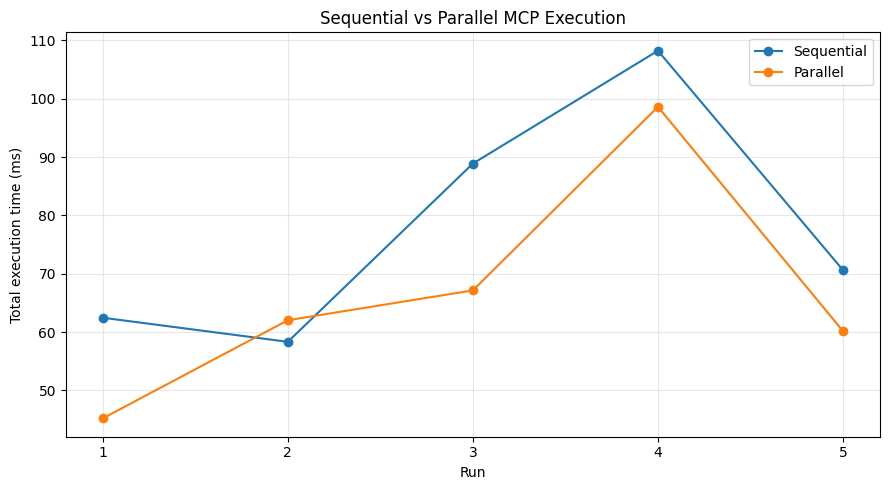

Graph saved to: /content/mcp_logs/performance_comparison.png


In [ ]:
seq_times = performance_df["Sequential Time (ms)"].tolist()
par_times = performance_df["Parallel Time (ms)"].tolist()

avg_seq = statistics.mean(seq_times)
avg_par = statistics.mean(par_times)
avg_per_tool_seq = avg_seq / len(independent_tasks)
time_reduction = ((avg_seq - avg_par) / avg_seq * 100) if avg_seq else 0

performance_summary = {
    "number_of_tasks": len(independent_tasks),
    "number_of_runs": len(performance_rows),
    "average_sequential_time_ms": round(avg_seq, 3),
    "average_parallel_time_ms": round(avg_par, 3),
    "average_sequential_time_per_tool_ms": round(avg_per_tool_seq, 3),
    "time_reduction_percent": round(time_reduction, 2)
}

print("Performance summary:")
print(json.dumps(performance_summary, indent=2))

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))
plt.plot(
    performance_df["Run"],
    performance_df["Sequential Time (ms)"],
    marker="o",
    label="Sequential"
)
plt.plot(
    performance_df["Run"],
    performance_df["Parallel Time (ms)"],
    marker="o",
    label="Parallel"
)
plt.xlabel("Run")
plt.ylabel("Total execution time (ms)")
plt.title("Sequential vs Parallel MCP Execution")
plt.xticks(performance_df["Run"])
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

PERFORMANCE_GRAPH = LOG_DIR / "performance_comparison.png"
plt.savefig(PERFORMANCE_GRAPH, dpi=150)
plt.show()

print("Graph saved to:", PERFORMANCE_GRAPH)

In [ ]:
results_observations = [
    {
        "Test": "MCP tool discovery",
        "Input": "session.list_tools()",
        "Observed Result": (
            ", ".join(sorted(DISCOVERED_TOOLS))
        ),
        "Passed": EXPECTED_TOOLS.issubset(DISCOVERED_TOOLS)
    },
    {
        "Test": "Python AST analysis",
        "Input": "analyze_python(calculator.py)",
        "Observed Result": (
            f"{analysis_result['function_count']} functions, "
            f"{analysis_result['class_count']} classes"
        ),
        "Passed": (
            analysis_result["function_count"] == 5
            and analysis_result["class_count"] == 0
        )
    },
    {
        "Test": "Automated testing",
        "Input": "run_tests",
        "Observed Result": test_result.get("stdout", "").strip(),
        "Passed": test_result.get("return_code") == 0
    },
    {
        "Test": "Path traversal",
        "Input": "../../etc/passwd",
        "Observed Result": server_security_result["data"].get("error"),
        "Passed": server_security_result["data"].get("status") == "error"
    },
    {
        "Test": "Dependency workflow",
        "Input": "Parallel analysis and search, then tests",
        "Observed Result": (
            "Tests executed after validation"
            if workflow_result["tests_executed"]
            else "Dependency workflow did not complete"
        ),
        "Passed": workflow_result["tests_executed"]
    },
    {
        "Test": "Performance comparison",
        "Input": "Four independent tools, five runs",
        "Observed Result": (
            f"Sequential average {avg_seq:.3f} ms; "
            f"parallel average {avg_par:.3f} ms"
        ),
        "Passed": len(performance_rows) == 5
    }
]

results_df = pd.DataFrame(results_observations)
display(results_df)

print("All passed:", bool(results_df["Passed"].all()))

,Test,Input,Observed Result,Passed
0,MCP tool discovery,session.list_tools(),"analyze_python, list_files, read_file, run_tes...",True
1,Python AST analysis,analyze_python(calculator.py),"5 functions, 0 classes",True
2,Automated testing,run_tests,...... ...,True
3,Path traversal,../../etc/passwd,Path outside project,True
4,Dependency workflow,"Parallel analysis and search, then tests",Tests executed after validation,True
5,Performance comparison,"Four independent tools, five runs",Sequential average 77.704 ms; parallel average...,True


All passed: True


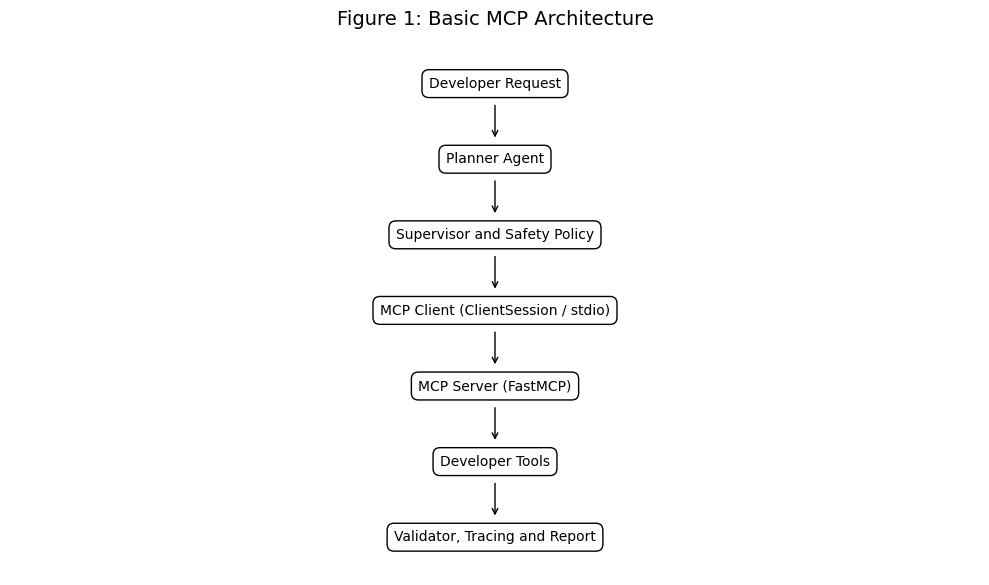

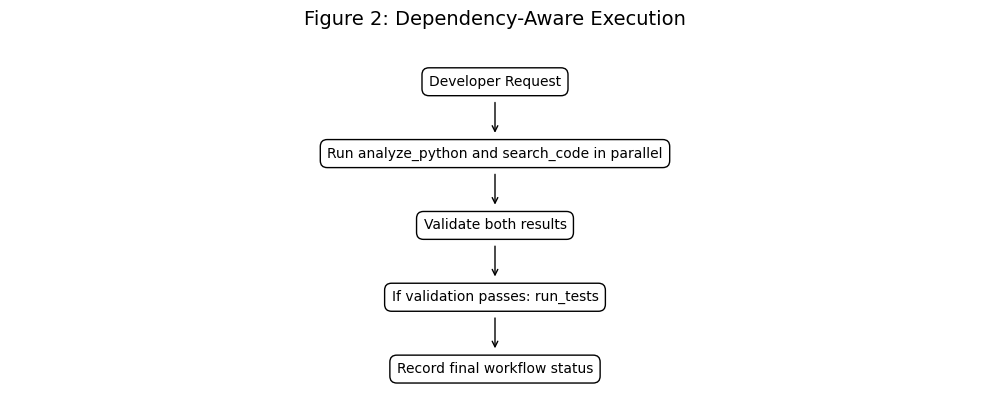

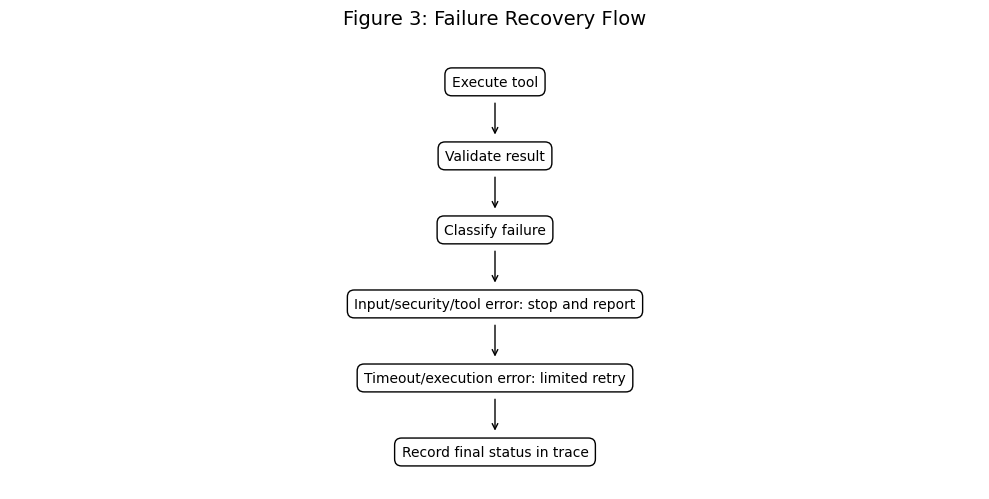

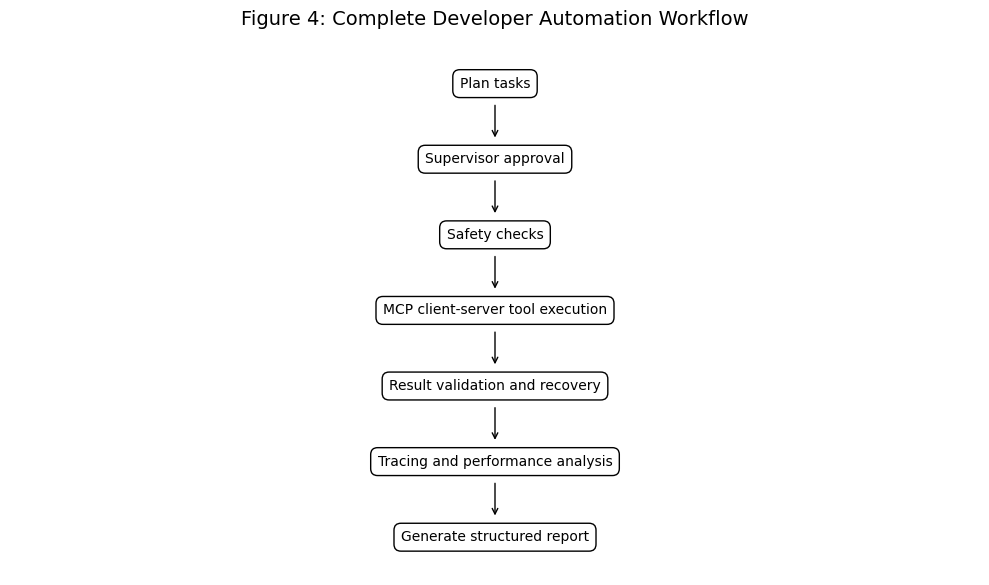

Generated architecture and workflow diagrams.


In [ ]:
def draw_workflow(title, boxes, filename):
    fig, ax = plt.subplots(figsize=(10, max(3, len(boxes) * 0.85)))
    ax.set_xlim(0, 10)
    ax.set_ylim(0, len(boxes))
    ax.axis("off")
    ax.set_title(title, fontsize=14, pad=15)

    positions = []
    for i, label in enumerate(boxes):
        y = len(boxes) - i - 0.5
        positions.append((5, y))
        ax.text(
            5, y, label,
            ha="center", va="center",
            bbox=dict(boxstyle="round,pad=0.5", fill=False),
            fontsize=10
        )

    for i in range(len(positions) - 1):
        x1, y1 = positions[i]
        x2, y2 = positions[i + 1]
        ax.annotate(
            "",
            xy=(x2, y2 + 0.25),
            xytext=(x1, y1 - 0.25),
            arrowprops=dict(arrowstyle="->")
        )

    fig.tight_layout()
    output_path = LOG_DIR / filename
    fig.savefig(output_path, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    return output_path


architecture_path = draw_workflow(
    "Figure 1: Basic MCP Architecture",
    [
        "Developer Request",
        "Planner Agent",
        "Supervisor and Safety Policy",
        "MCP Client (ClientSession / stdio)",
        "MCP Server (FastMCP)",
        "Developer Tools",
        "Validator, Tracing and Report"
    ],
    "figure_1_mcp_architecture.png"
)

dependency_path = draw_workflow(
    "Figure 2: Dependency-Aware Execution",
    [
        "Developer Request",
        "Run analyze_python and search_code in parallel",
        "Validate both results",
        "If validation passes: run_tests",
        "Record final workflow status"
    ],
    "figure_2_dependency_workflow.png"
)

recovery_path = draw_workflow(
    "Figure 3: Failure Recovery Flow",
    [
        "Execute tool",
        "Validate result",
        "Classify failure",
        "Input/security/tool error: stop and report",
        "Timeout/execution error: limited retry",
        "Record final status in trace"
    ],
    "figure_3_failure_recovery.png"
)

complete_workflow_path = draw_workflow(
    "Figure 4: Complete Developer Automation Workflow",
    [
        "Plan tasks",
        "Supervisor approval",
        "Safety checks",
        "MCP client-server tool execution",
        "Result validation and recovery",
        "Tracing and performance analysis",
        "Generate structured report"
    ],
    "figure_4_complete_workflow.png"
)

print("Generated architecture and workflow diagrams.")

In [ ]:
def load_jsonl(path):
    records = []
    if path.exists():
        for line in path.read_text(encoding="utf-8").splitlines():
            if line.strip():
                try:
                    records.append(json.loads(line))
                except json.JSONDecodeError:
                    logger.warning("Skipped malformed trace line.")
    return records


trace_records = load_jsonl(TRACE_FILE)

successful_trace_count = sum(
    item.get("execution_status") == "success"
    for item in trace_records
)
failed_trace_count = sum(
    item.get("execution_status") != "success"
    for item in trace_records
)

all_checks = {
    "five_mcp_tools_discovered": EXPECTED_TOOLS.issubset(DISCOVERED_TOOLS),
    "initial_tool_checks_passed": all(
        result["status"] == "success"
        for result in tool_checks.values()
    ),
    "ast_analysis_validated": validation_examples["analysis"][0],
    "automated_tests_passed": test_result.get("return_code") == 0,
    "path_traversal_blocked": not approved or (
        server_security_result["data"].get("status") == "error"
    ),
    "dependency_workflow_passed": (
        workflow_result["tests_executed"]
        and workflow_result["test_validation"]["passed"]
    ),
    "performance_runs_completed": len(performance_rows) == 5,
    "all_performance_calls_succeeded": bool(
        performance_df["Sequential Success"].all()
        and performance_df["Parallel Success"].all()
    )
}

developer_report = {
    "project": "DevPilot MCP",
    "experiment": "Experiment 06",
    "generated_at": datetime.now(timezone.utc).isoformat(),
    "architecture": "FastMCP server and ClientSession client over stdio",
    "discovered_tools": sorted(DISCOVERED_TOOLS),
    "initial_tool_results": {
        name: result["status"]
        for name, result in tool_checks.items()
    },
    "analysis_result": analysis_result,
    "test_result": test_result,
    "security_test": server_security_result["data"],
    "dependency_workflow": {
        "analysis_validation": workflow_result["analysis_validation"],
        "search_validation": workflow_result["search_validation"],
        "tests_executed": workflow_result["tests_executed"],
        "test_validation": workflow_result.get("test_validation")
    },
    "performance": performance_summary,
    "trace_summary": {
        "trace_file": str(TRACE_FILE),
        "total_records": len(trace_records),
        "successful_records": successful_trace_count,
        "failed_records": failed_trace_count
    },
    "checks": all_checks,
    "overall_pass": all(all_checks.values())
}

complete_report = {
    **developer_report,
    "sequential_parallel_runs": performance_rows,
    "results_observations": results_observations,
    "artifacts_directory": str(LOG_DIR)
}

execution_summary = {
    "project": "DevPilot MCP",
    "overall_pass": all(all_checks.values()),
    "passed_checks": sum(all_checks.values()),
    "total_checks": len(all_checks),
    "checks": all_checks,
    "average_sequential_ms": round(avg_seq, 3),
    "average_parallel_ms": round(avg_par, 3),
    "time_reduction_percent": round(time_reduction, 2),
    "trace_records": len(trace_records)
}

report_paths = {
    "developer_automation_report.json": developer_report,
    "experiment_06_complete_report.json": complete_report,
    "experiment_06_execution_summary.json": execution_summary
}

for filename, content in report_paths.items():
    path = LOG_DIR / filename
    path.write_text(json.dumps(content, indent=2), encoding="utf-8")
    print("Generated:", path)

print("\nExecution summary:")
print(json.dumps(execution_summary, indent=2))

Generated: /content/mcp_logs/developer_automation_report.json
Generated: /content/mcp_logs/experiment_06_complete_report.json
Generated: /content/mcp_logs/experiment_06_execution_summary.json

Execution summary:
{
  "project": "DevPilot MCP",
  "overall_pass": true,
  "passed_checks": 8,
  "total_checks": 8,
  "checks": {
    "five_mcp_tools_discovered": true,
    "initial_tool_checks_passed": true,
    "ast_analysis_validated": true,
    "automated_tests_passed": true,
    "path_traversal_blocked": true,
    "dependency_workflow_passed": true,
    "performance_runs_completed": true,
    "all_performance_calls_succeeded": true
  },
  "average_sequential_ms": 77.704,
  "average_parallel_ms": 66.628,
  "time_reduction_percent": 14.25,
  "trace_records": 55
}


In [ ]:

# CELL 24: FINAL VALIDATION CHECKS

print("=" * 60)
print("FINAL VALIDATION CHECKS")
print("=" * 60)

# Recheck supervisor security using a fresh unsafe-path task.
final_security_task = {
    "task_id": "FINAL-SECURITY-CHECK",
    "tool": "read_file",
    "arguments": {"file_path": "../../etc/passwd"},
    "depends_on": []
}

security_approved, security_reason = supervisor(final_security_task)

final_checks = {
    "MCP server and client initialized": (
        session is not None
    ),

    "All five tools discovered": (
        EXPECTED_TOOLS.issubset(DISCOVERED_TOOLS)
    ),

    "All five initial tool calls succeeded": (
        len(tool_checks) == 5
        and all(
            result.get("status") == "success"
            for result in tool_checks.values()
        )
    ),

    "AST analysis found five functions": (
        analysis_result.get("function_count") == 5
    ),

    "Automated tests returned code zero": (
        test_result.get("return_code") == 0
    ),

    "Unsafe path rejected by supervisor": (
        not security_approved
    ),

    "Unsafe path rejected by MCP server": (
        server_security_result.get("status") != "success"
        and server_security_result.get("data", {}).get("status") == "error"
        and "Path outside project"
        in server_security_result.get("data", {}).get("error", "")
    ),

    "Dependency-aware workflow passed": (
        workflow_result.get("tests_executed", False)
        and workflow_result.get("analysis_validation", {}).get("passed", False)
        and workflow_result.get("search_validation", {}).get("passed", False)
        and workflow_result.get("test_validation", {}).get("passed", False)
    ),

    "Five performance runs completed": (
        len(performance_rows) == 5
    ),

    "All sequential and parallel calls succeeded": (
        performance_df["Sequential Success"].all()
        and performance_df["Parallel Success"].all()
    ),

    "Trace file generated": (
        TRACE_FILE.exists()
    ),

    "Performance graph generated": (
        PERFORMANCE_GRAPH.exists()
    ),

    "Architecture diagrams generated": (
        architecture_path.exists()
        and dependency_path.exists()
        and recovery_path.exists()
        and complete_workflow_path.exists()
    )
}

print("\nSUPERVISOR SECURITY CHECK")
print("Decision:", "APPROVED" if security_approved else "REJECTED")
print("Reason:", security_reason)

print("\n" + "=" * 60)
print("FINAL CHECK RESULTS")
print("=" * 60)

for check_name, passed in final_checks.items():
    print(f"{'PASS' if passed else 'FAIL'} | {check_name}")

passed_count = sum(bool(value) for value in final_checks.values())
total_count = len(final_checks)

print("\n" + "=" * 60)
print(f"FINAL STATUS: {passed_count}/{total_count} checks passed.")

if passed_count == total_count:
    print("All final verification checks passed.")
else:
    print("Review the failed checks before reporting the experiment as complete.")

print("=" * 60)


FINAL VALIDATION CHECKS

SUPERVISOR SECURITY CHECK
Decision: REJECTED
Reason: Rejected: unsafe or invalid file path

FINAL CHECK RESULTS
PASS | MCP server and client initialized
PASS | All five tools discovered
PASS | All five initial tool calls succeeded
PASS | AST analysis found five functions
PASS | Automated tests returned code zero
PASS | Unsafe path rejected by supervisor
PASS | Unsafe path rejected by MCP server
PASS | Dependency-aware workflow passed
PASS | Five performance runs completed
PASS | All sequential and parallel calls succeeded
PASS | Trace file generated
PASS | Performance graph generated
PASS | Architecture diagrams generated

FINAL STATUS: 13/13 checks passed.
All final verification checks passed.


In [ ]:
final_trace_records = load_jsonl(TRACE_FILE)

# Ensure all check results are serialized as native Python types to avoid NumPy serialization errors
clean_checks = {key: bool(val) for key, val in final_checks.items()}

final_summary = {
    "project": "DevPilot MCP",
    "experiment": "Experiment 06",
    "generated_at": datetime.now(timezone.utc).isoformat(),
    "overall_pass": bool(all(clean_checks.values())),
    "passed_checks": int(sum(clean_checks.values())),
    "total_checks": len(clean_checks),
    "checks": clean_checks,
    "performance": performance_summary,
    "trace_records": len(final_trace_records),
    "successful_trace_records": int(sum(
        r.get("execution_status") == "success"
        for r in final_trace_records
    )),
    "failed_trace_records": int(sum(
        r.get("execution_status") != "success"
        for r in final_trace_records
    ))
}

final_summary_path = LOG_DIR / "experiment_06_execution_summary.json"
final_summary_path.write_text(
    json.dumps(final_summary, indent=2),
    encoding="utf-8"
)

developer_report["checks"] = clean_checks
developer_report["overall_pass"] = bool(all(clean_checks.values()))
developer_report["performance"] = performance_summary
developer_report["trace_summary"] = {
    "total_records": len(final_trace_records),
    "successful_records": final_summary["successful_trace_records"],
    "failed_records": final_summary["failed_trace_records"]
}

(LOG_DIR / "developer_automation_report.json").write_text(
    json.dumps(developer_report, indent=2),
    encoding="utf-8"
)

complete_report.update(developer_report)
complete_report["sequential_parallel_runs"] = performance_rows
complete_report["results_observations"] = results_observations

(LOG_DIR / "experiment_06_complete_report.json").write_text(
    json.dumps(complete_report, indent=2),
    encoding="utf-8"
)

artifact_rows = [
    ("execution.log", "Execution and error log"),
    ("mcp_traces.jsonl", "Persistent trace records"),
    ("developer_automation_report.json", "Developer automation report"),
    ("experiment_06_complete_report.json", "Complete experiment report"),
    ("experiment_06_execution_summary.json", "Final status and metrics"),
    ("performance_comparison.png", "Measured performance graph"),
    ("figure_1_mcp_architecture.png", "MCP architecture diagram"),
    ("figure_2_dependency_workflow.png", "Dependency workflow diagram"),
    ("figure_3_failure_recovery.png", "Failure recovery diagram"),
    ("figure_4_complete_workflow.png", "Complete workflow diagram")
]

artifact_df = pd.DataFrame([
    {
        "Artifact": filename,
        "Purpose": purpose,
        "Generated": (LOG_DIR / filename).exists()
    }
    for filename, purpose in artifact_rows
])

display(artifact_df)

assert artifact_df["Generated"].all(), (
    "One or more expected artifacts are missing."
)
print("PASS: All expected artifacts have been generated.")

,Artifact,Purpose,Generated
0,execution.log,Execution and error log,True
1,mcp_traces.jsonl,Persistent trace records,True
2,developer_automation_report.json,Developer automation report,True
3,experiment_06_complete_report.json,Complete experiment report,True
4,experiment_06_execution_summary.json,Final status and metrics,True
5,performance_comparison.png,Measured performance graph,True
6,figure_1_mcp_architecture.png,MCP architecture diagram,True
7,figure_2_dependency_workflow.png,Dependency workflow diagram,True
8,figure_3_failure_recovery.png,Failure recovery diagram,True
9,figure_4_complete_workflow.png,Complete workflow diagram,True


PASS: All expected artifacts have been generated.
